# Staircase analysis (test 2 / 3)

Analyses a recording of `scripts/sysid/2_stair_vx.rhai` (or `3_stair_vy.rhai`
with `AXIS = "vy"`): delay, rise, gain, dead zone, saturation, coupling.

Run from `small_engine/` (the notebook reads `../recordings/`):

```
uv run --python 3.12 --with jupyter,pandas,matplotlib jupyter lab analysis/stair.ipynb
```

Steps: 1 check the raw data, 2 robot-frame velocities, 3 the steps one by one,
4 plateau table, 5 gain plot, 6 coupling plots, 7 what to write down.

**Commanded** below always means the `cmd_*` columns: what was sent this tick,
*after* the engine limits. If `max_speed` / `max_accel` were not raised, the
steps are ramps and the high levels are clipped; section 1 flags that.

In [1]:
import glob, os, tomllib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- settings -------------------------------------------------------------
FILES = ["../recordings/stair_vx.csv"]   # one file per repeat; all are pooled
AXIS = "vx"              # "vx" (test 2, forward) or "vy" (test 3, sideways)
TAU_TEST1 = None         # delay from test 1 (s), to compare; None = unknown

FIELD_HALF_LENGTH = 4.5  # m, from small_engine.toml [control]
FIELD_HALF_WIDTH = 3.0
ROBOT_RADIUS = 0.09      # m

SMOOTH = 5               # frames in the centred moving average (3-5)
GLITCH_SPEED = 5.0       # m/s between two frames above this = misdetection
GLITCH_OMEGA = 25.0      # rad/s between two frames above this = misdetection
MIN_CONFIDENCE = 0.5
GAP_FRAMES = 4           # more frame numbers than this between two recorded frames = gap
FRAME_CLOCK = True       # time vision frames by frame number (fixed camera rate), not t_capture

DELAY_THR = 0.05         # m/s: motion starts when the speed moved this much (at most half the level)
SETTLE_DRIFT = 0.1       # plateau change over its window > this * level ...
SETTLE_MIN = 0.05        # ... and > this (m/s) = not settled
SETTLE_WINDOW = 0.3      # s: a shorter plateau window = not settled
STOP_TOL = 0.03          # m/s: below this counts as stopped
DEAD_TOL = 0.02          # m/s: plateau below this counts as not moving
# ---------------------------------------------------------------------------

MAIN, OTHER = ("fwd", "side") if AXIS == "vx" else ("side", "fwd")
CMD = "cmd_" + AXIS
NAME = {"fwd": "forward", "side": "sideways", "rot": "rotation"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Check the raw data first

Two time bases: the engine tick (`time`, one row per tick at 60 Hz, holds the
commands) and the vision frames (`frame`, `t_capture`; a frame repeats on
ticks with no new detection). The camera runs at a fixed rate, so each frame's
time is taken from its frame number, fitted to `t_capture` (`FRAME_CLOCK`):
`t_capture` itself jitters by a few ms, which over a 17-33 ms frame interval
is a large velocity error. Vision is then moved onto the engine clock with the
smallest `time - t` seen, so the delays below include the radio and the robot
but (almost) none of the vision transport.

In [2]:
def load(path):
    d = pd.read_csv(path)
    stem = os.path.splitext(path)[0]
    # limits: <name>.meta.toml, else the meta whose unix_start is within 5 s
    # of the first capture time (for a renamed csv)
    meta = {}
    t_first = d.t_capture.dropna().iloc[0]
    for m in [stem + ".meta.toml"] + sorted(glob.glob(os.path.join(os.path.dirname(path), "*.meta.toml"))):
        if os.path.exists(m):
            with open(m, "rb") as fh:
                cand = tomllib.load(fh)
            if m == stem + ".meta.toml" or abs(cand.get("unix_start", 0) - t_first) < 5:
                meta = cand
                meta["_file"] = os.path.basename(m)
                break
    # vision frames: first row of each new frame number
    seen = d[d.seen == 1]
    f = seen[seen.frame != seen.frame.shift()].copy()
    period, start = np.polyfit(f.frame, f.t_capture, 1)
    t_fit = start + period * f.frame
    f["jitter"] = f.t_capture - t_fit
    t = t_fit if FRAME_CLOCK else f.t_capture
    f["t"] = t + (f.time - t).min()
    f["theta_u"] = np.unwrap(f.theta.to_numpy())
    f = f[["t", "frame", "confidence", "x", "y", "theta", "theta_u", "vx", "vy", "omega", "jitter"]].reset_index(drop=True)
    return d, f, meta

runs = [load(p) for p in FILES]
for p, (d, f, meta) in zip(FILES, runs):
    print(f"{p}: {len(d)} ticks, {len(f)} vision frames, {d.time.iloc[-1] - d.time.iloc[0]:.1f} s,"
          f" meta {meta.get('_file', 'none')}")
    if meta:
        print("   limits: max_speed", meta.get("max_speed"), " max_accel", meta.get("max_accel"),
              " kalman", meta.get("kf_enabled"))

../recordings/stair_vx.csv: 3550 ticks, 2518 vision frames, 59.2 s, meta rec_1795538729.meta.toml
   limits: max_speed 1  max_accel 2  kalman True


**Checks:** vision glitches (jumps, low confidence), gaps (dropped frames),
frame timing, distance to the field edge, and whether the limits shaped the
steps. Glitch frames are dropped from everything below; velocities across a
gap are left empty.

In [3]:
def check(d, f, meta):
    dt = np.diff(f.t)
    med = np.median(dt)
    step = np.hypot(np.diff(f.x), np.diff(f.y)) / np.maximum(dt, 1e-6)
    turn = np.abs(np.diff(f.theta_u)) / np.maximum(dt, 1e-6)
    glitch = np.zeros(len(f), bool)
    # a misdetection makes a jump in and a jump out: flag frames with both
    big = (step > GLITCH_SPEED) | (turn > GLITCH_OMEGA)
    glitch[1:-1] = big[:-1] & big[1:]
    glitch |= (f.confidence < MIN_CONFIDENCE).to_numpy()
    fstep = np.diff(f.frame)
    gap = np.r_[False, fstep > GAP_FRAMES]
    f["glitch"], f["gap"] = glitch, gap

    tick = np.diff(d.time)
    edge_x = FIELD_HALF_LENGTH - f.x.abs().max()
    edge_y = FIELD_HALF_WIDTH - f.y.abs().max()
    period = np.median(dt / fstep)
    print(f"camera: {period*1000:.2f} ms per frame ({1/period:.1f} Hz); t_capture jitter around that"
          f" {f.jitter.std()*1000:.1f} ms std, {f.jitter.abs().max()*1000:.1f} ms max")
    print(f"recorded frames: every {np.mean(fstep):.2f} camera frames on average"
          f" (frame number steps: {dict(pd.Series(fstep).value_counts().sort_index().head(5))})")
    print(f"engine tick interval:  median {np.median(tick)*1000:.1f} ms, max {tick.max()*1000:.1f} ms")
    print(f"glitch frames: {glitch.sum()}   gaps (> {GAP_FRAMES} frames): {gap.sum()}   vision lost on {int((d.seen == 0).sum())} ticks")
    print(f"area used: x {f.x.min():+.2f}..{f.x.max():+.2f}  y {f.y.min():+.2f}..{f.y.max():+.2f} m;"
          f" closest to the edge {min(edge_x, edge_y):.2f} m"
          + ("  <-- TOO CLOSE, check for contact" if min(edge_x, edge_y) < ROBOT_RADIUS + 0.05 else ""))
    if meta:
        lim = meta.get("max_speed", np.inf)
        acc = meta.get("max_accel", np.inf)
        if acc < 20:
            print(f"NOTE: max_accel was {acc} m/s^2: each step is a ramp of ~{1/acc:.2f} s per m/s,"
                  " not a sharp step (delay is still measured, against the ramp)")
        top = d[CMD].abs().max()
        if top >= lim - 1e-6:
            print(f"NOTE: max_speed was {lim} m/s: levels above it were clipped to {lim};"
                  " saturation of the robot cannot be seen above that")
    return f

runs = [(d, check(d, f, meta), meta) for d, f, meta in runs]

camera: 16.67 ms per frame (60.0 Hz); t_capture jitter around that 2.3 ms std, 6.4 ms max
recorded frames: every 1.41 camera frames on average (frame number steps: {1: np.int64(1485), 2: np.int64(1032)})
engine tick interval:  median 16.7 ms, max 19.3 ms
glitch frames: 0   gaps (> 4 frames): 0   vision lost on 0 ticks
area used: x -0.64..+0.59  y -0.06..+0.04 m; closest to the edge 2.94 m
NOTE: max_accel was 2 m/s^2: each step is a ramp of ~0.50 s per m/s, not a sharp step (delay is still measured, against the ramp)
NOTE: max_speed was 1 m/s: levels above it were clipped to 1; saturation of the robot cannot be seen above that


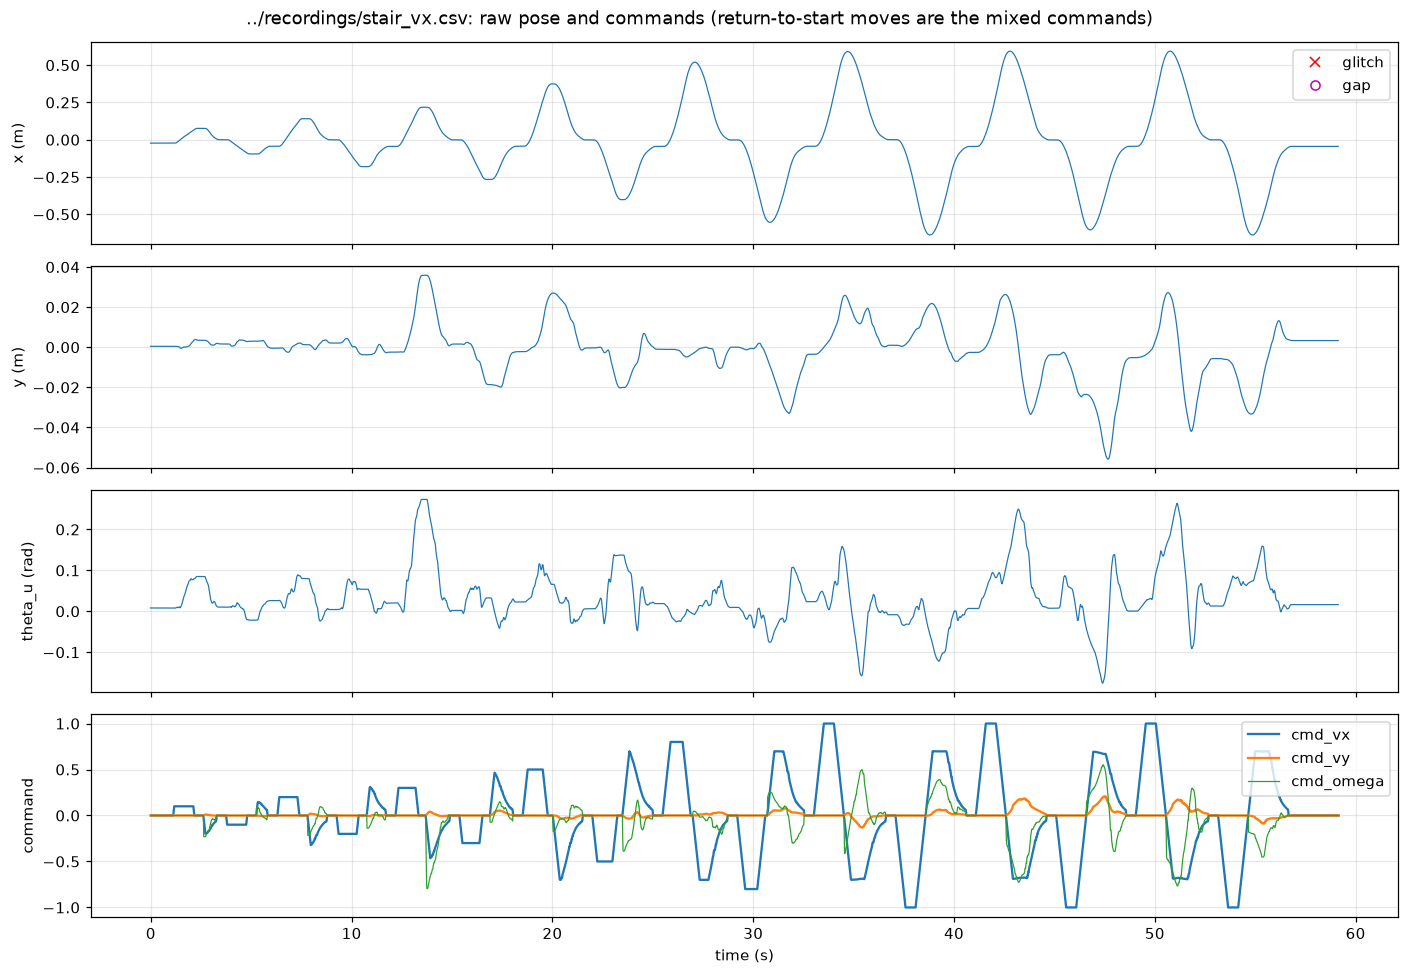

In [4]:
for p, (d, f, meta) in zip(FILES, runs):
    fig, ax = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
    t0 = d.time.iloc[0]
    for a, col, unit in [(ax[0], "x", "m"), (ax[1], "y", "m"), (ax[2], "theta_u", "rad")]:
        a.plot(f.t - t0, f[col], lw=0.8)
        a.plot((f.t - t0)[f.glitch], f[col][f.glitch], "rx", label="glitch")
        a.plot((f.t - t0)[f.gap], f[col][f.gap], "mo", mfc="none", label="gap")
        a.set_ylabel(f"{col} ({unit})")
    ax[0].legend(loc="upper right")
    ax[3].plot(d.time - t0, d.cmd_vx, label="cmd_vx")
    ax[3].plot(d.time - t0, d.cmd_vy, label="cmd_vy")
    ax[3].plot(d.time - t0, d.cmd_omega, label="cmd_omega", lw=0.8)
    ax[3].set_ylabel("command"); ax[3].set_xlabel("time (s)"); ax[3].legend(loc="upper right")
    fig.suptitle(f"{p}: raw pose and commands (return-to-start moves are the mixed commands)")
    fig.tight_layout()

## 2. Robot-frame velocities

Centred moving average of x, y, θ over `SMOOTH` frames (centred, so no lag),
differentiated against the capture time, then rotated by θ into the robot frame:

  fwd = cos θ · ẋ + sin θ · ẏ,  side = −sin θ · ẋ + cos θ · ẏ,  rot = θ̇

The engine's own Kalman estimate (rotated the same way) is drawn for comparison.

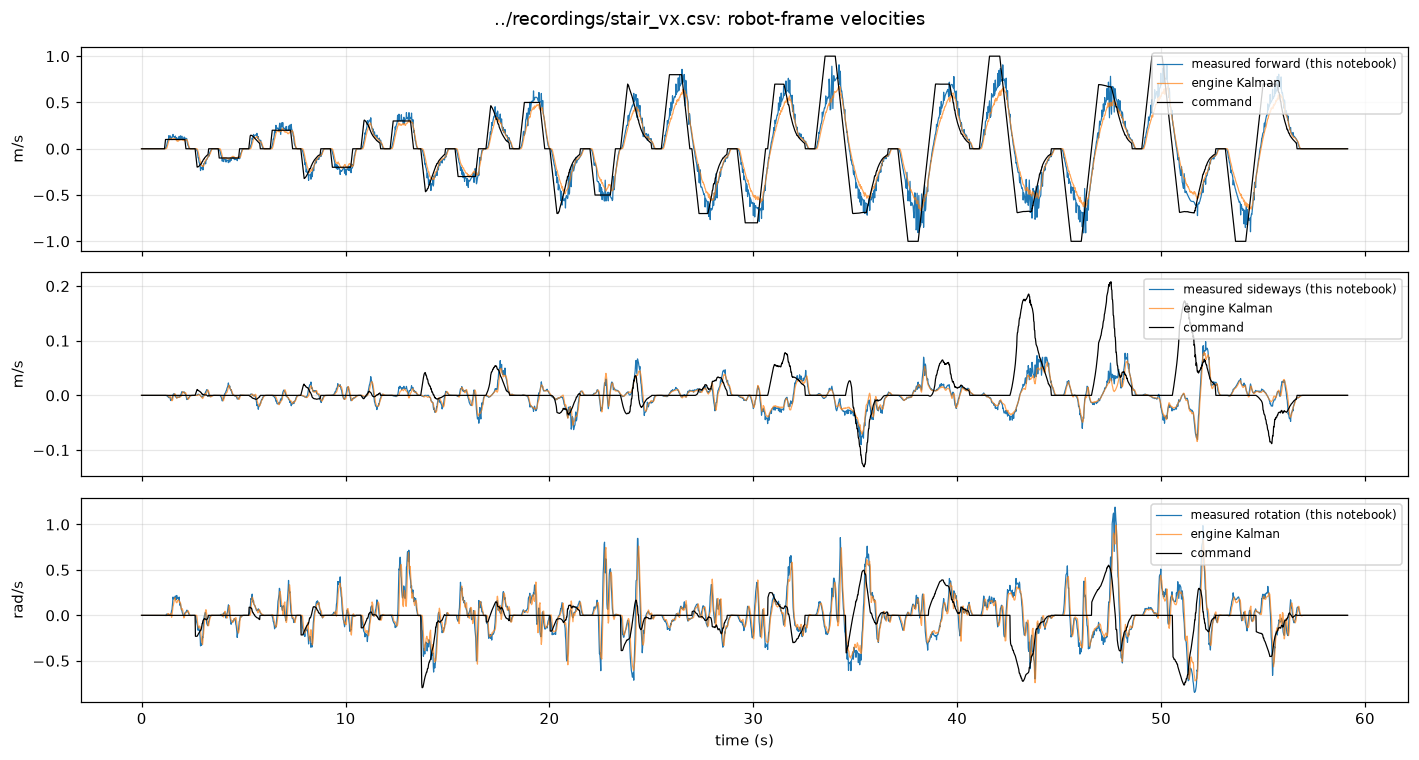

In [5]:
def velocities(d, f):
    g = f[~f.glitch].reset_index(drop=True)
    sm = lambda s: s.rolling(SMOOTH, center=True, min_periods=1).mean().to_numpy()
    t, x, y, th = g.t.to_numpy(), sm(g.x), sm(g.y), sm(g.theta_u)
    xd, yd, thd = np.gradient(x, t), np.gradient(y, t), np.gradient(th, t)
    c, s = np.cos(g.theta_u), np.sin(g.theta_u)
    g["fwd"], g["side"], g["rot"] = c * xd + s * yd, -s * xd + c * yd, thd
    g["kf_fwd"], g["kf_side"] = c * g.vx + s * g.vy, -s * g.vx + c * g.vy
    # empty across gaps (the gap frame and its neighbours)
    bad = g.gap | g.gap.shift(-1, fill_value=False)
    g.loc[bad, ["fwd", "side", "rot"]] = np.nan
    # command in force at each frame (last tick at or before it)
    cmd = d[["time", "cmd_vx", "cmd_vy", "cmd_omega", "mode"]]
    return pd.merge_asof(g, cmd, left_on="t", right_on="time", direction="backward")

vel = [velocities(d, f) for d, f, _ in runs]

g, d = vel[0], runs[0][0]
t0 = d.time.iloc[0]
fig, ax = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for a, k in zip(ax, ["fwd", "side", "rot"]):
    a.plot(g.t - t0, g[k], lw=0.8, label=f"measured {NAME[k]} (this notebook)")
    if k != "rot":
        a.plot(g.t - t0, g["kf_" + k], lw=0.8, alpha=0.7, label="engine Kalman")
    else:
        a.plot(g.t - t0, g.omega, lw=0.8, alpha=0.7, label="engine Kalman")
    cmdcol = {"fwd": "cmd_vx", "side": "cmd_vy", "rot": "cmd_omega"}[k]
    a.plot(d.time - t0, d[cmdcol], "k", lw=0.8, label="command")
    a.set_ylabel("rad/s" if k == "rot" else "m/s"); a.legend(loc="upper right", fontsize=8)
ax[-1].set_xlabel("time (s)")
fig.suptitle(f"{FILES[0]}: robot-frame velocities")
fig.tight_layout()

## 3. The steps one by one

A step is a run of `local_vel` ticks (a `vel` command); the moves back to the
start are `world_vel` and are ignored. Per step:

- **τ (delay):** time from the *command* crossing a threshold to the *measured*
  speed crossing the same threshold, two frames in a row (works for ramps too).
  Threshold: `DELAY_THR` (at most half the level) away from the speed before
  the step.
- **rise:** measured speed from 10% to 90% of its plateau.
- **overshoot:** peak beyond the plateau, % of the plateau.
- **plateau window:** from the 90% point (and not before the command reached
  its level + τ) to the end of the hold + τ.
- **drift:** slope of the measured speed over the plateau window (m/s per s).
- **settled:** the speed reached 90%, the window is at least `SETTLE_WINDOW`
  long, and the speed changed less than `SETTLE_DRIFT`·level (or `SETTLE_MIN`)
  over it. Steps that did not settle never levelled off (holds too
  short, or the command was still ramping): they are shown but left out of the
  gain and coupling fits.
- **stop:** time from the command leaving the plateau to |speed| < `STOP_TOL`;
  **reverse:** largest speed the other way while stopping; **coast:** distance
  travelled after the command left the plateau. All until the next command
  (the move back to the start).

In [6]:
def steps(d, g, run):
    lv = (d["mode"] == "local_vel").to_numpy()
    starts = np.flatnonzero(lv & ~np.r_[False, lv[:-1]])
    ends = np.flatnonzero(lv & ~np.r_[lv[1:], False])
    rows = []
    for i0, i1 in zip(starts, ends):
        seg = d.iloc[i0:i1 + 1]
        level = seg[CMD].iloc[np.argmax(seg[CMD].abs().to_numpy())]
        sgn = np.sign(level)
        t_on, t_off = seg.time.iloc[0], seg.time.iloc[-1] + 1 / 60
        before = g[(g.t > t_on - 0.2) & (g.t <= t_on)][MAIN].mean()
        thr = min(DELAY_THR, 0.5 * abs(level))
        # command crossing (ticks) and measured crossing (frames)
        c_cross = seg.time[(sgn * seg[CMD]) >= thr]
        w = g[(g.t >= t_on) & (g.t <= t_off + 1.0)]
        above = (sgn * (w[MAIN] - before)) >= thr
        m_cross = w.t[above & above.shift(-1, fill_value=False)]
        tau = (m_cross.iloc[0] - c_cross.iloc[0]) if len(c_cross) and len(m_cross) else np.nan
        tau_ = 0.0 if np.isnan(tau) else tau
        hold = g[(g.t >= t_on) & (g.t <= t_off + tau_)]
        late = hold[hold.t >= t_on + 0.7 * (t_off + tau_ - t_on)]
        pre = late[MAIN].median()
        frac = (sgn * hold[MAIN]) / abs(pre) if pre else pd.Series(np.nan, index=hold.index)
        t10 = hold.t[frac >= 0.1]; t90 = hold.t[frac >= 0.9]
        t_level = seg.time[seg[CMD] == level].iloc[0] + tau_
        t_set = max(t90.iloc[0], t_level) if len(t90) else late.t.iloc[0]
        win = hold[hold.t >= t_set]
        if len(win) < 5:
            win = late
        plateau = win[MAIN].mean()
        drift = np.polyfit(win.t, win[MAIN], 1)[0] if len(win) > 3 else np.nan
        span = win.t.iloc[-1] - win.t.iloc[0]
        settled = (bool(len(t90)) and span >= SETTLE_WINDOW
                   and abs(drift * span) < max(SETTLE_DRIFT * abs(level), SETTLE_MIN))
        pk = g[(g.t >= t_on) & (g.t <= t_off + tau_ + 0.3)][MAIN].rolling(3, center=True).median()
        peak = (sgn * pk).max()
        nxt = d.time[(d.time > t_off) & (d["mode"] != "idle")]
        t_next = min(nxt.iloc[0] if len(nxt) else np.inf, t_off + 1.5)
        after = g[(g.t >= t_off) & (g.t <= t_next)]
        still = after.t[after[MAIN].abs() < STOP_TOL]
        t_stop = still.iloc[0] - t_off if len(still) else np.nan
        stop_end = still.iloc[0] if len(still) else after.t.iloc[-1]
        a2 = g[(g.t >= t_off) & (g.t <= stop_end)]
        coast = np.trapezoid(a2[MAIN], a2.t) if len(a2) > 1 else np.nan
        rows.append(dict(
            run=run, t_on=t_on, t_off=t_off, cmd=level, cmd_plateau_s=float((seg[CMD] == level).sum() / 60),
            tau=tau, rise=(t90.iloc[0] - t10.iloc[0]) if len(t10) and len(t90) else np.nan,
            overshoot=100 * (peak / abs(plateau) - 1) if plateau else np.nan,
            settled=settled, meas=plateau, meas_std=win[MAIN].std(), drift=drift,
            other=win[OTHER].mean(), other_std=win[OTHER].std(),
            rot=win.rot.mean(), rot_std=win.rot.std(),
            t_stop=t_stop, reverse=max(0.0, (-sgn * after[MAIN]).max()), coast=coast,
            win_start=t_set, win_end=t_off + tau_))
    return pd.DataFrame(rows)

S = pd.concat([steps(d, g, i) for i, ((d, _, _), g) in enumerate(zip(runs, vel))], ignore_index=True)
print(f"{len(S)} steps; levels: {sorted(float(c) for c in S.cmd.round(3).unique())}")
OK, nb_ = S[S.settled], S[~S.settled]
if len(nb_):
    print(f"NOT SETTLED ({len(nb_)}): cmd {', '.join(f'{c:+g}' for c in nb_.cmd)}"
          " -> lengthen `hold` (and raise max_accel); left out of the fits")

16 steps; levels: [-1.0, -0.8, -0.5, -0.3, -0.2, -0.1, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0]
NOT SETTLED (9): cmd -0.5, +0.8, -0.8, +1, -1, +1, -1, +1, -1 -> lengthen `hold` (and raise max_accel); left out of the fits


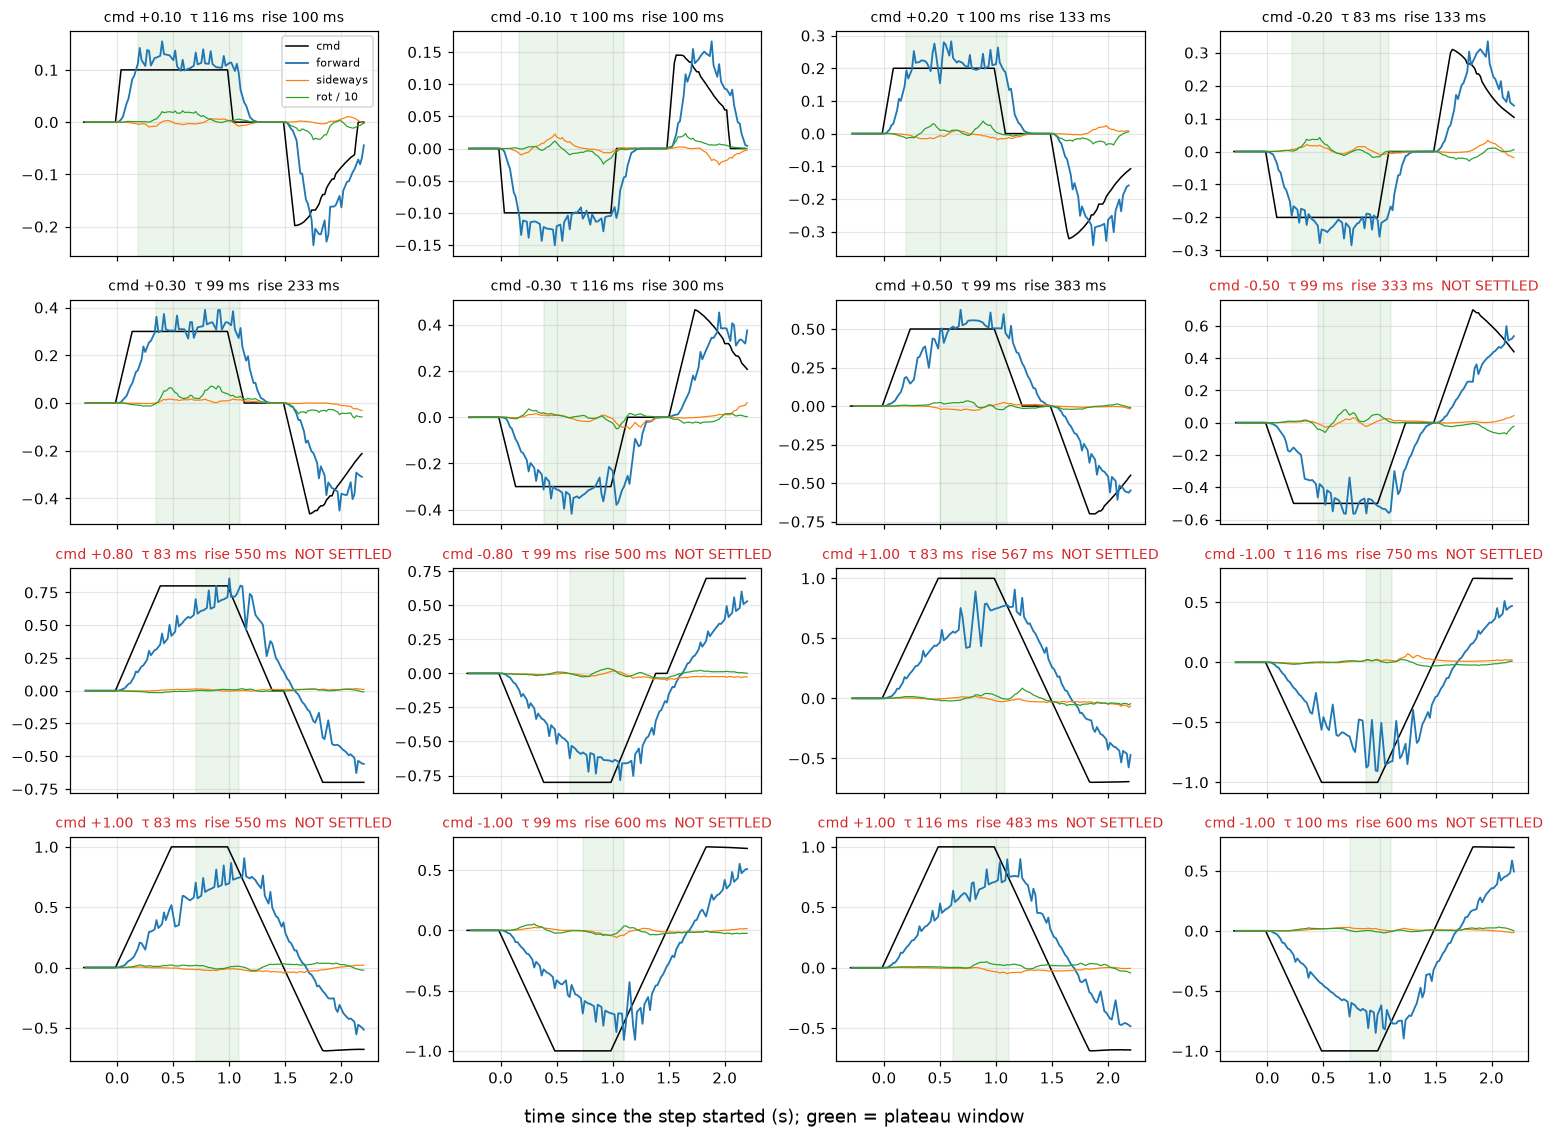

In [7]:
n = len(S); cols = 4; rws = int(np.ceil(n / cols))
fig, axs = plt.subplots(rws, cols, figsize=(14, 2.6 * rws), sharex=True)
for a, (_, s) in zip(axs.flat, S.iterrows()):
    d, g = runs[int(s.run)][0], vel[int(s.run)]
    dd = d[(d.time >= s.t_on - 0.3) & (d.time <= s.t_off + 1.2)]
    gg = g[(g.t >= s.t_on - 0.3) & (g.t <= s.t_off + 1.2)]
    a.plot(dd.time - s.t_on, dd[CMD], "k", lw=1, label="cmd")
    a.plot(gg.t - s.t_on, gg[MAIN], lw=1.2, label=NAME[MAIN])
    a.plot(gg.t - s.t_on, gg[OTHER], lw=0.8, label=NAME[OTHER])
    a.plot(gg.t - s.t_on, gg.rot / 10, lw=0.8, label="rot / 10")
    a.axvspan(s.win_start - s.t_on, s.win_end - s.t_on, color="g", alpha=0.08)
    a.set_title(f"cmd {s.cmd:+.2f}  τ {s.tau*1000:.0f} ms  rise {s.rise*1000:.0f} ms"
                + ("" if s.settled else "  NOT SETTLED"), fontsize=9, color="k" if s.settled else "C3")
for a in axs.flat[n:]:
    a.axis("off")
axs.flat[0].legend(fontsize=7)
fig.supxlabel("time since the step started (s); green = plateau window")
fig.tight_layout()

**Forward vs backward:** each level's + step and the mirrored − step on top of
each other. Mirror images = symmetric robot.

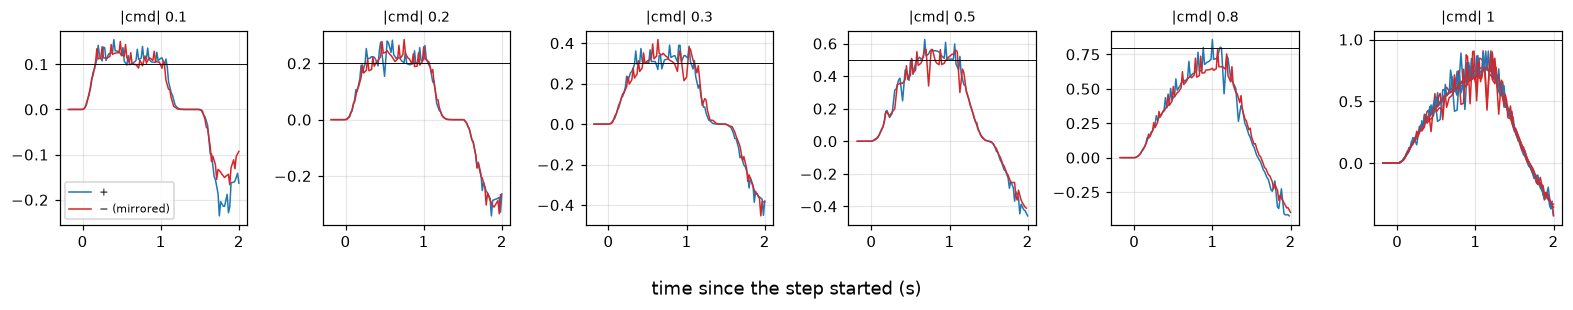

In [8]:
levels = sorted(S.cmd.abs().round(3).unique())
fig, axs = plt.subplots(1, len(levels), figsize=(2.4 * len(levels), 2.8), sharey=False)
for a, L in zip(np.atleast_1d(axs), levels):
    for _, s in S[S.cmd.abs().round(3) == L].iterrows():
        g = vel[int(s.run)]
        gg = g[(g.t >= s.t_on - 0.2) & (g.t <= s.t_off + 1.0)]
        sgn = np.sign(s.cmd)
        a.plot(gg.t - s.t_on, sgn * gg[MAIN], color="C0" if sgn > 0 else "C3", lw=1,
               label="+" if sgn > 0 else "− (mirrored)")
    a.axhline(L, color="k", lw=0.6)
    a.set_title(f"|cmd| {L:g}", fontsize=9)
h, l = np.atleast_1d(axs)[0].get_legend_handles_labels()
np.atleast_1d(axs)[0].legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), fontsize=7)
fig.supxlabel("time since the step started (s)")
fig.tight_layout()

## 4. Plateau table

One row per step. `meas` is the measured speed on the commanded axis,
`other` the other axis, `rot` the rotation, each averaged over the plateau
window; `_std` is the variation inside the window. `cmd_plateau_s` is how long
the command actually sat at its level (less than the hold when it was ramped).

In [9]:
cols = ["run", "cmd", "settled", "cmd_plateau_s", "meas", "meas_std", "other", "other_std", "rot", "rot_std",
        "tau", "rise", "overshoot", "drift", "t_stop", "reverse", "coast"]
T = S[cols].rename(columns={"meas": f"meas_{MAIN}", "meas_std": f"{MAIN}_std",
                            "other": f"meas_{OTHER}", "other_std": f"{OTHER}_std"})
T.round(3)

,run,cmd,settled,cmd_plateau_s,meas_fwd,fwd_std,meas_side,side_std,rot,rot_std,tau,rise,overshoot,drift,t_stop,reverse,coast
0,0,0.1,True,0.967,0.116,0.017,-0.001,0.005,0.093,0.079,0.116,0.100,17.406,-0.029,0.183,0.0,0.011
1,0,-0.1,True,0.967,-0.112,0.019,0.003,0.008,-0.039,0.075,0.100,0.100,12.867,0.039,0.133,0.0,-0.008
2,0,0.2,True,0.917,0.221,0.030,-0.007,0.008,0.087,0.139,0.100,0.133,23.527,-0.004,0.216,0.0,0.027
3,0,-0.2,True,0.917,-0.217,0.027,0.006,0.010,0.064,0.178,0.083,0.133,10.534,-0.024,0.233,0.0,-0.029
4,0,0.3,True,0.867,0.327,0.033,0.011,0.005,0.388,0.192,0.099,0.233,19.187,0.025,0.283,0.0,0.051
5,0,-0.3,True,0.867,-0.321,0.044,-0.006,0.015,-0.021,0.166,0.116,0.300,14.806,0.017,0.299,0.0,-0.055
6,0,0.5,True,0.767,0.525,0.045,-0.011,0.017,0.081,0.183,0.099,0.383,5.985,0.069,0.416,0.0,0.120
7,0,-0.5,False,0.767,-0.493,0.060,-0.001,0.019,0.182,0.399,0.099,0.333,14.367,-0.140,0.416,0.0,-0.113
8,0,0.8,False,0.617,0.693,0.072,0.004,0.006,0.044,0.038,0.083,0.550,15.012,0.359,NaN,0.0,0.239
9,0,-0.8,False,0.617,-0.629,0.060,-0.004,0.013,0.023,0.206,0.099,0.500,4.977,-0.244,NaN,0.0,-0.244


## 5. Gain plot: commanded vs measured

Gain = slope. Fitted separately for forward (+) and backward (−), through the
origin, using only settled steps that moved (|meas| > `DEAD_TOL`). Not
settled steps are drawn as hollow grey markers. The second plot is
measured / commanded per step: flat = one gain is enough; a trend = the gain
depends on speed (use a lookup table); a drop at the top = saturation.

gain forward 1.067   gain backward 1.078
dead zone: moves at every level, so the dead zone is below 0.1 m/s
highest settled level 0.5 m/s: gain there 1.050 vs low levels 1.110  -> no saturation up to here
levels above 0.5 did not settle: saturation can't be judged there


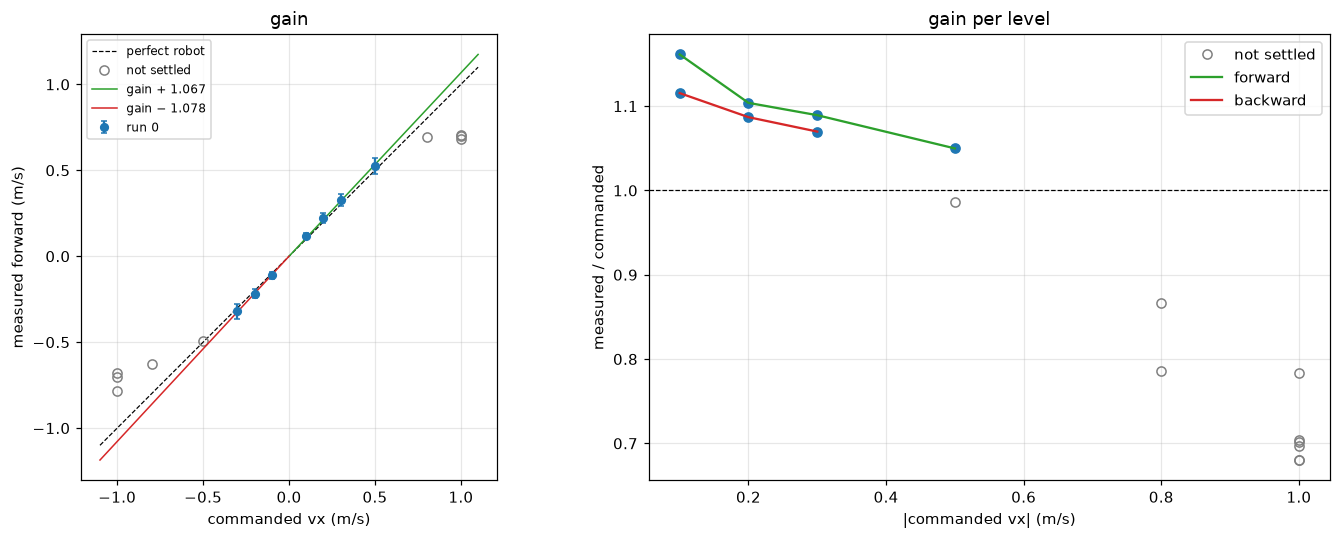

In [10]:
mv = OK[OK.meas.abs() > DEAD_TOL]
gain = {}
for name, part in [("forward (+)", mv[mv.cmd > 0]), ("backward (−)", mv[mv.cmd < 0])]:
    gain[name] = (part.cmd * part.meas).sum() / (part.cmd ** 2).sum() if len(part) else np.nan

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5))
lim = S.cmd.abs().max() * 1.1
a.plot([-lim, lim], [-lim, lim], "k--", lw=0.8, label="perfect robot")
for r in sorted(S.run.unique()):
    s = OK[OK.run == r]
    a.errorbar(s.cmd, s.meas, yerr=s.meas_std, fmt="o", ms=5, capsize=2, label=f"run {r}")
a.plot(nb_.cmd, nb_.meas, "o", mfc="none", color="gray", label="not settled")
xs = np.linspace(0, lim, 2)
a.plot(xs, gain["forward (+)"] * xs, "C2", lw=1, label=f"gain + {gain['forward (+)']:.3f}")
a.plot(-xs, -gain["backward (−)"] * xs, "C3", lw=1, label=f"gain − {gain['backward (−)']:.3f}")
a.set_xlabel(f"commanded {AXIS} (m/s)"); a.set_ylabel(f"measured {NAME[MAIN]} (m/s)")
a.set_aspect("equal"); a.legend(fontsize=8); a.set_title("gain")

ratio = OK.meas / OK.cmd
b.plot(OK.cmd.abs(), ratio, "o")
b.plot(nb_.cmd.abs(), nb_.meas / nb_.cmd, "o", mfc="none", color="gray", label="not settled")
for sg, c in [(1, "C2"), (-1, "C3")]:
    s = OK[np.sign(OK.cmd) == sg]
    m = s.groupby(s.cmd.abs().round(3)).apply(lambda q: (q.meas / q.cmd).mean())
    b.plot(m.index, m.values, "-", color=c, label="forward" if sg > 0 else "backward")
b.axhline(1, color="k", lw=0.8, ls="--")
b.set_xlabel(f"|commanded {AXIS}| (m/s)"); b.set_ylabel("measured / commanded"); b.legend()
b.set_title("gain per level")
fig.tight_layout()

moving = OK.groupby(OK.cmd.abs().round(3)).meas.apply(lambda m: (m.abs() > DEAD_TOL).all())
first_move = moving[moving].index.min()
not_moving = moving[~moving].index.max() if (~moving).any() else None
print(f"gain forward {gain['forward (+)']:.3f}   gain backward {gain['backward (−)']:.3f}")
print("dead zone:", f"no motion up to {not_moving} m/s, moves from {first_move} m/s" if not_moving is not None
      else f"moves at every level, so the dead zone is below {first_move} m/s")
top = OK.cmd.abs().max()
r_lo = ratio[OK.cmd.abs() <= 0.5 * top].abs().median()
r_hi = ratio[OK.cmd.abs() == top].abs().median()
print(f"highest settled level {top:g} m/s: gain there {r_hi:.3f} vs low levels {r_lo:.3f}"
      + ("  -> saturating" if r_hi < 0.9 * r_lo else "  -> no saturation up to here"))
if len(nb_):
    print(f"levels above {top:g} did not settle: saturation can't be judged there")

**Repeat consistency:** the same level measured more than once (several
files, or levels clipped to the same value). Spread = std across repeats.

In [11]:
R = S.groupby(S.cmd.round(3)).agg(n=("meas", "size"), settled=("settled", "sum"), meas_mean=("meas", "mean"), spread=("meas", "std"),
                                 tau_mean=("tau", "mean"), other_mean=("other", "mean"), rot_mean=("rot", "mean"))
R.round(3)

,n,settled,meas_mean,spread,tau_mean,other_mean,rot_mean
cmd,,,,,,,
-1.0,3,0,-0.722,0.055,0.105,0.002,-0.060
-0.8,1,0,-0.629,NaN,0.099,-0.004,0.023
-0.5,1,0,-0.493,NaN,0.099,-0.001,0.182
-0.3,1,1,-0.321,NaN,0.116,-0.006,-0.021
-0.2,1,1,-0.217,NaN,0.083,0.006,0.064
-0.1,1,1,-0.112,NaN,0.100,0.003,-0.039
0.1,1,1,0.116,NaN,0.116,-0.001,0.093
0.2,1,1,0.221,NaN,0.100,-0.007,0.087
0.3,1,1,0.327,NaN,0.099,0.011,0.388


## 6. Coupling plots

Ideally flat at zero. Fitted line `a·cmd + b`: `a` is the proportional
coupling (the off-diagonal matrix entry), `b` a constant bias, and the
residual scatter is slip or noise that only feedback can handle.

sideways: -0.006 m/s per m/s of vx, bias -0.000 m/s, scatter 0.008 -> scatter / none
rotation: +0.272 rad/s per m/s of vx, bias +0.074 rad/s, scatter 0.117 -> scatter / none


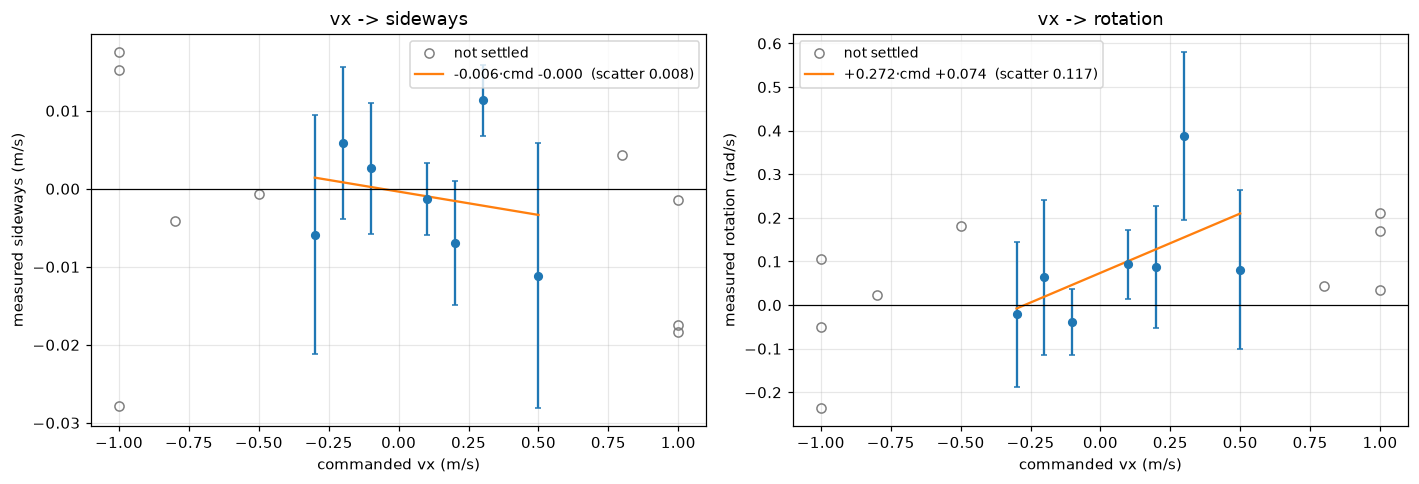

In [12]:
coup = {}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for a, k, unit in [(axs[0], "other", "m/s"), (axs[1], "rot", "rad/s")]:
    label = NAME[OTHER] if k == "other" else "rotation"
    a.errorbar(OK.cmd, OK[k], yerr=OK[k + "_std"], fmt="o", ms=5, capsize=2)
    a.plot(nb_.cmd, nb_[k], "o", mfc="none", color="gray", label="not settled")
    slope, bias = np.polyfit(OK.cmd, OK[k], 1)
    resid = (OK[k] - (slope * OK.cmd + bias)).std()
    coup[label] = (slope, bias, resid)
    xs = np.linspace(OK.cmd.min(), OK.cmd.max(), 2)
    a.plot(xs, slope * xs + bias, "C1", label=f"{slope:+.3f}·cmd {bias:+.3f}  (scatter {resid:.3f})")
    a.axhline(0, color="k", lw=0.8)
    a.set_xlabel(f"commanded {AXIS} (m/s)"); a.set_ylabel(f"measured {label} ({unit})")
    a.legend(fontsize=9); a.set_title(f"{AXIS} -> {label}")
fig.tight_layout()

for label, (slope, bias, resid) in coup.items():
    unit = "rad/s" if label == "rotation" else "m/s"
    kind = ("proportional coupling" if abs(slope) * OK.cmd.abs().max() > 2 * max(abs(bias), resid)
            else "bias" if abs(bias) > 2 * resid else "scatter / none")
    print(f"{label}: {slope:+.3f} {unit} per m/s of {AXIS}, bias {bias:+.3f} {unit}, scatter {resid:.3f} -> {kind}")

## 7. What to write down

In [13]:
fmt = lambda v, u="": "n/a" if v is None or (isinstance(v, float) and np.isnan(v)) else f"{v:.3f}{u}"
tau = S.tau.median()
print(f"delay τ                 {fmt(tau, ' s')}  (spread {fmt(S.tau.std(), ' s')} over levels)"
      + (f"; test 1 gave {TAU_TEST1:.3f} s" if TAU_TEST1 else "; compare with test 1"))
print(f"rise 10-90%             {fmt(S.rise.median(), ' s')} median, overshoot {S.overshoot.median():.0f}% median")
print(f"settled steps           {len(OK)} of {len(S)}" + ("" if len(OK) == len(S) else "  -> lengthen hold / raise max_accel"))
print(f"stop                    {fmt(S.t_stop.median(), ' s')} median, reverse {fmt(S.reverse.max(), ' m/s')} max,"
      f" coast {fmt(S.coast.abs().max(), ' m')} max")
print(f"gain forward            {fmt(gain['forward (+)'])}")
print(f"gain backward           {fmt(gain['backward (−)'])}")
print(f"dead zone               " + (f"{not_moving} .. {first_move} m/s" if not_moving is not None else f"< {first_move} m/s"))
print(f"real max speed          {fmt(OK.meas.abs().max(), ' m/s')} settled (highest commanded {S.cmd.abs().max():g})")
for label, (slope, bias, resid) in coup.items():
    unit = "rad/s" if label == "rotation" else "m/s"
    print(f"{label:<12} per m/s   {slope:+.3f} {unit}  (bias {bias:+.3f}, scatter {resid:.3f})")
rep = R[R.n > 1]
print("repeat spread           " + (f"{rep.spread.max():.3f} m/s worst over {len(rep)} repeated levels"
                                    if len(rep) else "no repeated levels: add more files to FILES"))

delay τ                 0.099 s  (spread 0.012 s over levels); compare with test 1
rise 10-90%             0.433 s median, overshoot 15% median
settled steps           7 of 16  -> lengthen hold / raise max_accel
stop                    0.258 s median, reverse 0.000 m/s max, coast 0.306 m max
gain forward            1.067
gain backward           1.078
dead zone               < 0.1 m/s
real max speed          0.525 m/s settled (highest commanded 1)
sideways     per m/s   -0.006 m/s  (bias -0.000, scatter 0.008)
rotation     per m/s   +0.272 rad/s  (bias +0.074, scatter 0.117)
repeat spread           0.055 m/s worst over 2 repeated levels
